<a href="https://colab.research.google.com/github/gabrielndouna/spotify-data-analysis-2025/blob/main/Analyse_spotify_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎵 Analyse de la Popularité Spotify (2025) : Loi des Artistes & Loi de Pareto

## 📌 Contexte & Objectifs du Projet
Ce notebook présente une étude exploratoire des **730 chansons les plus écoutées sur Spotify en 2025**.

L'objectif de cette étude est d'analyser la dynamique de consommation musicale à travers deux prismes analytiques majeurs :
1. **La Loi des Artistes (Concentration des talents) :** Identifier les superstars qui dominent le classement et évaluer le degré de concentration du catalogue.
2. **Le Principe de Pareto (Règle des 80/20) :** Déterminer si le Top 20% des chansons concentre l'essentiel du volume global des écoutes (`Spotify Streams`).

---

## 🛠️ Plan de l'Analyse
1. **Chargement & Exploration Initiale (EDA) :** Vérification de la structure du fichier, des types de variables et validation de la propreté des données.
2. **Analyse de la Loi des Artistes :**
   * Identification du Top 10 des artistes ayant le plus de titres dans le classement.
   * Calcul du volume total de streams accumulé par artiste.
3. **Analyse de Pareto & Segmentation :**
   * Tri des chansons par nombre d'écoutes (`Spotify Streams`).
   * Découpage en 5 quintiles d'égale taille via `pd.qcut()`.
   * Calcul de la part de marché relative de chaque groupe.
4. **Visualisation Graphique & Synthèse :** Représentation des résultats avec `matplotlib` / `seaborn` et rédaction des conclusions stratégiques.

---

## 📦 Environnement & Bibliothèques
* **Language :** Python 3.x
* **Data Manipulation :** `pandas`
* **Data Visualization :** `matplotlib`, `seaborn`

## 1. Chargement & Exploration Initiale des Données (EDA)

Dans cette première phase, notre objectif est de charger le jeu de données et d'inspecter sa structure globale :
* **Importation des bibliothèques :** Chargement des outils principaux (`pandas` pour la manipulation de données et `matplotlib.pyplot` pour les visualisations).
* **Chargement du jeu de données :** Ingestion du fichier CSV `most_streamed_spotify_2025.csv`.
* **Inspection de la structure :**
  * Affichage des 5 premières lignes (`.head()`) pour appréhender les colonnes disponibles.
  * Vérification du résumé structural (`.info()`) pour contrôler les types de données (numériques, chaînes de caractères) et s'assurer de l'absence de valeurs manquantes.

##Importation des bibliothèques:


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('most_streamed_spotify_2025.csv')


* Affichage des 5 premières lignes

In [2]:
#afficher les 5 premieres lignes de notre dataset
df.head()

,rank,track,artist,billed_artist_count,is_collaboration,spotify_streams_total,daily_streams,daily_streams_rank,daily_stream_share_pct,wrapped_global_top10_rank
0,1,Ordinary,Alex Warren,1,False,1948570210,2333502,11,0.1198,4.0
1,2,DtMF,Bad Bunny,1,False,1912497312,3017476,3,0.1578,5.0
2,3,Golden,HUNTR/X,1,False,1759912501,2286960,14,0.1299,7.0
3,4,BAILE INoLVIDABLE,Bad Bunny,1,False,1553054400,2624716,7,0.1690,NaN
4,5,The Fate of Ophelia,Taylor Swift,1,False,1425834222,3046797,2,0.2137,NaN


* Vérification du résumé structural (`.info()`) pour contrôler les types de données (numériques, chaînes de caractères) et s'assurer de l'absence de valeurs manquantes.


In [3]:
#Vérification du résumé structural
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   rank                       730 non-null    int64  
 1   track                      730 non-null    object 
 2   artist                     730 non-null    object 
 3   billed_artist_count        730 non-null    int64  
 4   is_collaboration           730 non-null    bool   
 5   spotify_streams_total      730 non-null    int64  
 6   daily_streams              730 non-null    int64  
 7   daily_streams_rank         730 non-null    int64  
 8   daily_stream_share_pct     730 non-null    float64
 9   wrapped_global_top10_rank  3 non-null      float64
dtypes: bool(1), float64(2), int64(5), object(2)
memory usage: 52.2+ KB


* **Détection des valeurs manquantes :**
  Afin de s'assurer de l'exhaustivité des données, nous calculons le nombre total de cellules vides (`NaN`) pour chaque colonne.

In [4]:
#nombre total de valeur manquante
df.isnull().sum()

,0
rank,0
track,0
artist,0
billed_artist_count,0
is_collaboration,0
spotify_streams_total,0
daily_streams,0
daily_streams_rank,0
daily_stream_share_pct,0
wrapped_global_top10_rank,727


* **Vérification des doublons :**
  Pour garantir l'exactitude des calculs et éviter de compter plusieurs fois la même chanson, nous contrôlons la présence de lignes en double dans le jeu de données.
  

In [5]:
df.duplicated().sum()

np.int64(0)

* **Résumé statistique des variables numériques :**
  Nous générons les indicateurs statistiques clés (moyenne, écart-type, minimum, quartiles et maximum) pour synthétiser la distribution des données quantitatives (notamment le volume de streams).

In [6]:
df.describe()

,rank,billed_artist_count,spotify_streams_total,daily_streams,daily_streams_rank,daily_stream_share_pct,wrapped_global_top10_rank
count,730.000000,730.000000,7.300000e+02,7.300000e+02,730.000000,730.000000,3.000000
mean,365.500000,1.031507,2.337006e+08,3.684854e+05,365.500000,0.145742,5.333333
std,210.877136,0.174803,2.075011e+08,4.639724e+05,210.877136,0.111047,1.527525
min,1.000000,1.000000,1.002850e+08,9.432000e+03,1.000000,0.008400,4.000000
25%,183.250000,1.000000,1.266382e+08,1.106278e+05,183.250000,0.072875,4.500000
50%,365.500000,1.000000,1.670339e+08,2.229660e+05,365.500000,0.120500,5.000000
75%,547.750000,1.000000,2.456286e+08,4.337102e+05,547.750000,0.182325,6.000000
max,730.000000,2.000000,1.948570e+09,3.075070e+06,730.000000,0.980200,7.000000


### 📝 Observations & Synthèse de l'Exploration (EDA)

* **Volume & Structure :** Le jeu de données contient **730 entrées** (chansons) et 9 colonnes.
* **Doublons :** Aucun doublon détecté (`0`). Chaque ligne représente une chanson unique.
* **Valeurs Manquantes :**
  * Les colonnes clés de l'analyse (`artist`, `track`, `spotify_streams_total`) sont **100% complètes** sans aucune valeur manquante.
  * La colonne `wrapped_global_top10_rank` présente **727 valeurs manquantes** (seules 3 chansons sont renseignées). Elle sera donc écartée de notre analyse.
* **Format des données :** Les métriques de streaming (`spotify_streams_total`) sont bien enregistrées sous forme d'entiers (`int64`), prêtes pour les calculs d'agrégation.

## 2. Analyse de la Loi des Artistes (Concentration des talents)

Dans cette section, nous étudions la présence des artistes au sein du classement des 730 titres les plus écoutés en 2025 :
* **Décompte des titres :** Compter le nombre de morceaux qu'un même artiste parvient à placer dans le classement.
* **Volume total cumulé :** Sommer le volume global de streams (`spotify_streams_total`) généré par l'ensemble des titres de chaque artiste.
* **Classement des artistes phares :** Identifier le Top 10 des artistes les plus représentés et les plus écoutés.

### 2.1 Top 10 des Artistes les plus représentés (par nombre de chansons)
Afin d'évaluer la concentration des artistes dans le classement, nous comptons le nombre de morceaux qu'un même artiste parvient à placer dans le Top 730 des chansons les plus écoutées.

In [7]:
count_artist=df.groupby('artist').size()
top_10_artist=count_artist.sort_values(ascending=False)[:10]
print(top_10_artist)


artist
Bad Bunny            15
Sabrina Carpenter    14
Taylor Swift         12
Neton Vega           10
Tate McRae           10
Olivia Dean           9
Fuerza Regida         9
Morgan Wallen         9
Peso Pluma            8
EsDeeKid              7
dtype: int64


### 2.2 Volume Total de Streams Cumulés par Artiste
Afin de mesurer l'impact réel des artistes sur la plateforme, nous calculons le volume global d'écoutes (`spotify_streams_total`) cumulé par l'ensemble des titres de chaque artiste.

In [8]:
top_10_artist_streams=df.groupby('artist')['spotify_streams_total'].sum().sort_values(ascending=False).head(10)
print(top_10_artist_streams)

artist
Bad Bunny            11246823766
Taylor Swift          4769621849
Sabrina Carpenter     4047388152
Olivia Dean           3776232333
HUNTR/X               3519605700
Tate McRae            3468687807
Fuerza Regida         3256811633
Alex Warren           2807625539
Neton Vega            2543530779
Morgan Wallen         2257716361
Name: spotify_streams_total, dtype: int64


### 2.3 Visualisation du Top 10 des Artistes
Afin d'illustrer la concentration des écoutes, nous présentons le Top 10 des artistes sous la forme d'un diagramme en barres à l'aide de Matplotlib.

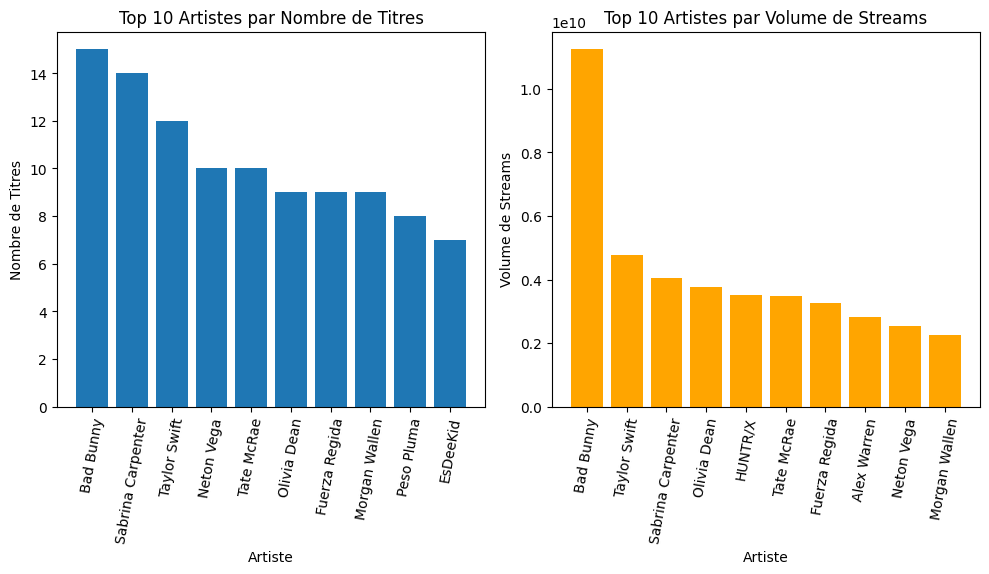

In [9]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.bar(top_10_artist.index, top_10_artist.values)
plt.title('Top 10 Artistes par Nombre de Titres')
plt.xlabel('Artiste')
plt.ylabel('Nombre de Titres')
plt.xticks(rotation=80)

plt.subplot(1,2,2)
plt.bar(top_10_artist_streams.index, top_10_artist_streams.values
        ,color='orange')
plt.title('Top 10 Artistes par Volume de Streams')
plt.xlabel('Artiste')
plt.ylabel('Volume de Streams')
plt.xticks(rotation=80)

plt.tight_layout()
plt.show()

### 📝 Observations & Synthèse : Loi des Artistes (Concentration des talents)

* **Volume de production vs Puissance d'écoute :** Le classement par nombre de chansons et celui par volume total de streams ne sont pas strictement identiques.
* **Le phénomène Bad Bunny :** Bad Bunny domine nettement les deux classements, se plaçant en première position à la fois en nombre de titres et en volume d'écoutes cumulées.
* **Effet "Super-Hit" vs "Catalogue" :**
  * Des artistes comme **Taylor Swift** ou **Sabrina Carpenter** maintiennent une présence forte sur les deux métriques.
  * À l'inverse, certains artistes placent un nombre plus restreint de titres dans le classement (ex: **HUNTR/X** ou **Alex Warren**), mais ceux-ci génèrent un volume de streams très élevé grâce à d'immenses hits viraux.
* **Conclusion :** La concentration des écoutes s'articule autour d'une poignée de superstars mondiales, complétée par des morceaux viraux à très fort volume individuel.

## 3. Analyse du Principe de Pareto (Règle des 80/20)

Dans cette section, nous cherchons à vérifier si la distribution des écoutes suit le **principe de Pareto** (environ 80 % des streams générés par 20 % des titres le plus populaires) :
1. **Tri des données :** Classement des 730 chansons par ordre décroissant de streams (`spotify_streams_total`).
2. **Segmentation en 5 tranches (Quintiles) :** Découpage du catalogue en 5 groupes d'égale taille (20 % des chansons chacun) grâce à `pd.qcut()`.
3. **Calcul des parts de marché :** Somme des écoutes par groupe et calcul du pourcentage du volume total qu'elles représentent.

### 3.1 Tri du Catalogue & Réinitialisation de l'Index (`sort_values`)

Afin de pouvoir segmenter correctement les données selon le principe de Pareto, nous ordonnons les 730 chansons de la plus écoutée à la moins écoutée. La réinitialisation de l'index permet à la chanson n°1 du classement de porter l'index `0`.

In [10]:
df_sorted=df.sort_values(by='spotify_streams_total',ascending=False)
df_sorted.reset_index(drop=True)
df_sorted.head()

,rank,track,artist,billed_artist_count,is_collaboration,spotify_streams_total,daily_streams,daily_streams_rank,daily_stream_share_pct,wrapped_global_top10_rank
0,1,Ordinary,Alex Warren,1,False,1948570210,2333502,11,0.1198,4.0
1,2,DtMF,Bad Bunny,1,False,1912497312,3017476,3,0.1578,5.0
2,3,Golden,HUNTR/X,1,False,1759912501,2286960,14,0.1299,7.0
3,4,BAILE INoLVIDABLE,Bad Bunny,1,False,1553054400,2624716,7,0.1690,NaN
4,5,The Fate of Ophelia,Taylor Swift,1,False,1425834222,3046797,2,0.2137,NaN


### 3.2 Segmentation du Catalogue en Quintiles (`pd.qcut`)

Afin d'analyser la répartition des écoutes, nous découpons nos 730 chansons en 5 groupes d'égale taille (chacun représentant 20 % du catalogue). Nous utilisons pour cela la fonction `pd.qcut()` qui affecte à chaque chanson une étiquette allant du Top 20% aux 20% les moins écoutés.

In [11]:
# Crée la colonne 'quintile' dans df_sorted
df_sorted['quintile'] = pd.qcut(
    df_sorted['spotify_streams_total'],
    q=5,
    labels=['5-Bas', '4-Moyen-Bas', '3-Moyen', '2-Haut', '1-Top 20%']
)

# Affiche les 5 premières lignes avec les colonnes de ton choix
df_sorted[['track', 'artist', 'spotify_streams_total', 'quintile']].head()

,track,artist,spotify_streams_total,quintile
0,Ordinary,Alex Warren,1948570210,1-Top 20%
1,DtMF,Bad Bunny,1912497312,1-Top 20%
2,Golden,HUNTR/X,1759912501,1-Top 20%
3,BAILE INoLVIDABLE,Bad Bunny,1553054400,1-Top 20%
4,The Fate of Ophelia,Taylor Swift,1425834222,1-Top 20%


### 3.3 Agrégation des Streams & Part de Marché par Quintile (`groupby`)

Afin d'évaluer la concentration des écoutes, nous regroupons le catalogue par quintile pour calculer :
1. Le volume total d'écoutes cumulées par tranche.
2. Le pourcentage (part de marché) que chaque tranche représente par rapport au volume d'écoutes global.

In [12]:
total_streams=df_sorted['spotify_streams_total'].sum()
streams_by_quintile=df_sorted.groupby('quintile')['spotify_streams_total'].sum()
part_market=streams_by_quintile/total_streams*100
print(part_market)

quintile
5-Bas           9.494906
4-Moyen-Bas    11.435047
3-Moyen        14.321336
2-Haut         19.412955
1-Top 20%      45.335755
Name: spotify_streams_total, dtype: float64


/tmp/ipykernel_51104/1584948542.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  streams_by_quintile=df_sorted.groupby('quintile')['spotify_streams_total'].sum()


### 3.4 Visualisation de la Répartition des Streams par Quintile (Pie Chart)

Afin d'illustrer la part d'écoutes captée par chaque tranche du catalogue, nous représentons les parts de marché sous forme d'un diagramme en camembert (*Pie Chart*).

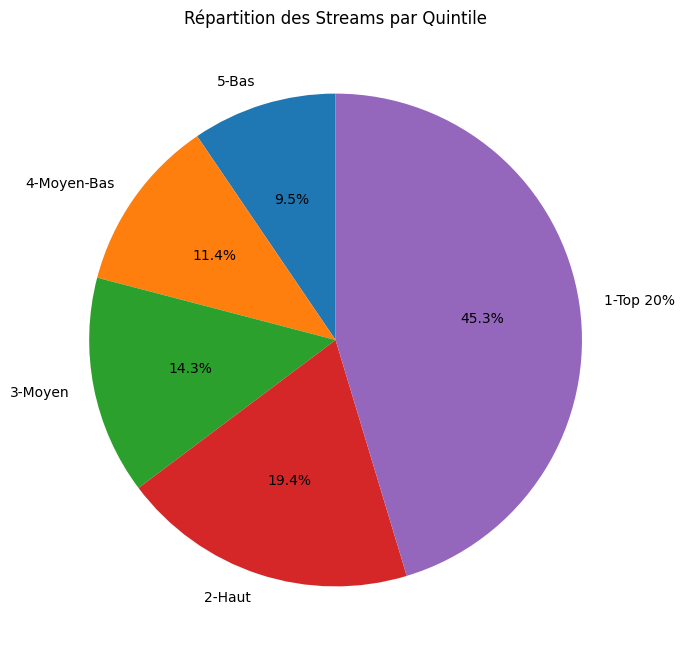

In [13]:
plt.figure(figsize=(8, 8))
plt.pie(part_market, labels=part_market.index, autopct='%1.1f%%', startangle=90)
plt.title('Répartition des Streams par Quintile')
plt.show()

### 📝 Observations & Synthèse : Principe de Pareto (Règle des 80/20)

* **Forte concentration sur le Top 20 % :** Le premier quintile (les 20 % de chansons les plus écoutées) capte à lui seul **45,3 %** du volume global d'écoutes cumulées.
* **Poids du Top 40 % :** Les deux premiers quintiles réunis (Top 40 % du catalogue) cumulent **64,7 %** des écoutes totales (45,3 % + 19,4 %).
* **Distribution en Longue Traîne (*Long Tail*) :** Les 60 % de chansons les moins écoutées du classement (Quintiles 3, 4 et 5) se partagent le reste du marché, soit **35,3 %** des écoutes (14,3 % + 11,4 % + 9,5 %).
* **Conclusion :** Bien que la règle stricte des 80/20 ne soit pas atteinte (80 % des écoutes générées par 20 % des titres), les données confirment une domination marquée du sommet du catalogue sur Spotify en 2025, où près de la moitié de l'attention des auditeurs est captée par seulement un cinquième des titres.

## 5. Conclusion Générale & Recommandations Stratégiques

### 5.1 Bilan Synthétique de l'Analyse
L'exploration du jeu de données Spotify 2025 à travers nos deux axes analytiques permet de tirer des conclusions claires sur la structure de la consommation musicale sur la plateforme :

1. **Loi des Artistes (Concentration des talents) :**
   * Le classement est dominé par un noyau de superstars internationales (notamment **Bad Bunny**, **Taylor Swift**, et **Sabrina Carpenter**).
   * L'analyse met en relief une dualité stratégique :
     * **Stratégie de catalogue :** Des artistes maintenant une forte présence grâce à un nombre élevé de morceaux classés.
     * **Stratégie de puissance virale :** Des artistes plaçant un nombre très restreint de titres mais générant des volumes d'écoutes massifs grâce à d'immenses hits.

2. **Principe de Pareto (Distribution des écoutes) :**
   * **Top 20 % du catalogue (Quintile 1) :** Concentre à lui seul **45,3 %** du volume global des streams.
   * **Top 40 % du catalogue (Quintiles 1 + 2) :** Représente **64,7 %** des écoutes totales.
   * **La Longue Traîne (Quintiles 3, 4 et 5) :** Les 60 % de morceaux les moins écoutés du classement conservent une part de marché cumulée significative de **35,3 %**.
   * **Bilan :** Bien que la règle théorique stricte du 80/20 ne soit pas atteinte, la distribution montre une polarisation marquée vers le sommet du catalogue.

---

### 5.2 Recommandations Stratégiques (Business & Data Science)

* **Pour la Programmation & Édition de Playlists (Marketing) :**
  * Exploiter la forte attractivité du **Top 20 %** pour maximiser le taux de rétention des auditeurs.
  * Utiliser les titres phares comme leviers pour créer des algorithmes de recommandation vers les titres de la **Longue Traîne** (60 % restants), favorisant ainsi la découverte d'artistes émergents.

* **Pour les Labels & Directeurs Artistiques (A&R) :**
  * Maintenir un portefeuille équilibré : combiner la recherche de superstars capables de viser le Quintile 1 avec la gestion d'un catalogue étendu générant des écoutes stables sur le long terme.

* **Pistes d'Approfondissement en Data Science :**
  * **Analyse audio :** Modéliser la relation entre les caractéristiques audio (tempo, *danceability*, valence) et la probabilité d'appartenir au Top 20 %.
  * **Analyse temporelle :** Étudier l'impact de la date de sortie sur la vitesse d'accumulation des streams pour mesurer la viabilité d'un morceau dans le temps.